## 1. The data

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ladder

ENCODE_ON_GPU = False  # late interaction: False downloads the token vectors (about 1.2 GB); True encodes them on your GPU

caiq, fiqa = ladder.load("caiq"), ladder.load("fiqa")
DATASETS = (caiq, fiqa)

In [2]:
for ds in DATASETS:
    words = [len(ladder.tokenize(t)) for t in ds.texts]
    rel = [sum(g > 0 for g in q.values()) for q in ds.qrels.values()]
    print(f"{ds.name}: {len(ds.ids):,} documents, {len(ds.queries)} questions, "
          f"median document {np.median(words):.0f} words, {np.mean(rel):.1f} relevant documents per question")

caiq: 644 documents, 119 questions, median document 24 words, 9.7 relevant documents per question


fiqa: 57,912 documents, 648 questions, median document 95 words, 2.6 relevant documents per question


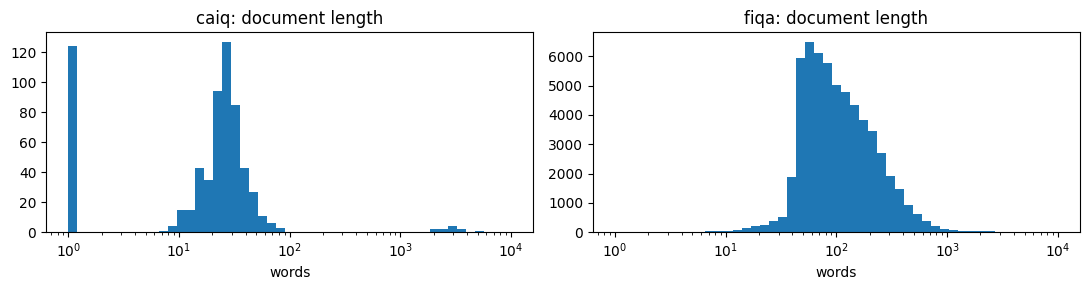

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, ds in zip(axes, DATASETS):
    words = np.array([len(ladder.tokenize(t)) for t in ds.texts])
    ax.hist(words, bins=np.logspace(0, 4, 50))
    ax.set_xscale("log")
    ax.set_title(f"{ds.name}: document length")
    ax.set_xlabel("words")
fig.tight_layout()

In [4]:
for ds in DATASETS:
    qid = next(iter(ds.queries))
    best = max(ds.qrels[qid], key=ds.qrels[qid].get)
    print(f"{ds.name} question: {ds.queries[qid]}")
    print(f"relevant (grade {ds.qrels[qid][best]}): {ds.titles[ds.row[best]]} {ds.texts[ds.row[best]][:300]}\n")

caiq question: For Fimil: Is a risk-based corrective action plan to remediate audit findings established, documented, approved, communicated, applied, evaluated, and maintained?
relevant (grade 1): Present SpA — A&A-06.1: Is a risk-based corrective action plan to remediate audit findings established, documented, approved, communicated, applied, evaluated, and maintained? Yes. Performed as part of ISO 27001:2013 standard certification.

fiqa question: How to deposit a cheque issued to an associate in my business into my business account?
relevant (grade 1):  Have the check reissued to the proper payee.



## 2. BM25

In [5]:
TEXT = {ds.name: ladder.bm25(ds, ds.texts) for ds in DATASETS}
runs = {ds.name: {"bm25 (text)": ladder.evaluate(ds, TEXT[ds.name])} for ds in DATASETS}
for ds in DATASETS:
    print(f"{ds.name}: nDCG@10 {np.mean(list(runs[ds.name]['bm25 (text)'].values())):.3f}")

caiq: nDCG@10 0.208
fiqa: nDCG@10 0.221


## 3. Add the title

caiq: text + title, IDF per field 0.472, IDF over title and text together 0.515


fiqa: text + title, IDF per field 0.221, IDF over title and text together 0.221


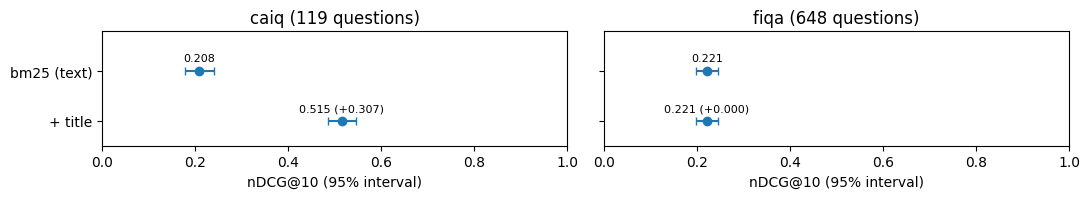

In [6]:
own = {ds.name: ladder.bm25(ds, ds.titles) for ds in DATASETS}  # the title's IDF from the titles alone
TEXT = {ds.name: ladder.bm25(ds, ds.texts, idf_texts=ds.title_text) for ds in DATASETS}  # from here on, every field's IDF
TITLE = {ds.name: ladder.bm25(ds, ds.titles, idf_texts=ds.title_text) for ds in DATASETS}  # comes from title and text together
for ds in DATASETS:
    per_field = ladder.evaluate(ds, ladder.bm25(ds, ds.texts) + own[ds.name])
    shared = ladder.evaluate(ds, TEXT[ds.name] + TITLE[ds.name])
    print(f"{ds.name}: text + title, IDF per field {np.mean(list(per_field.values())):.3f}, "
          f"IDF over title and text together {np.mean(list(shared.values())):.3f}")
    runs[ds.name]["+ title"] = shared
del own
ladder.plot_ladder(runs);

In [7]:
gain = {q: runs["caiq"]["+ title"][q] - runs["caiq"]["bm25 (text)"][q] for q in caiq.qids}
example = max(gain, key=gain.get)
ladder.show(caiq, example, {"bm25 (text)": TEXT["caiq"], "+ title": TEXT["caiq"] + TITLE["caiq"]})

q:fimil:HRS-01.1: For Fimil: Are background verification policies and procedures of all new employees established?

bm25 (text)  nDCG@10 0.000
  1. [.] fimil:HRS-01.1 Fimil — HRS-01.1: Are background verification policies and procedures of all new employees…
  2. [.] present:HRS-10.1 Present SpA — HRS-10.1: Are requirements for non-disclosure/confidentiality agreements ref…
  3. [.] fimil:IAM-06.1 Fimil — IAM-06.1: Is a user access provisioning process defined and implemented? Yes. Emai…
  4. [.] misc:007       Untitled Yes. Yes. Audit logs stored in PostgreSQL with database-level access controls. Ad…
  5. [.] octopus:STA-09.1 Octopus Deploy — STA-09.1: Do you mandate annual information security reviews and audits o…

+ title  nDCG@10 0.504
  1. [.] fimil:HRS-01.1 Fimil — HRS-01.1: Are background verification policies and procedures of all new employees…
  2. [1] present:HRS-01.1 Present SpA — HRS-01.1: Are background verification policies and procedures of all new emp…
  3. [1] fimil:

## 4. Let's look at the top matches

In [8]:
def saturated(ds, S):
    return TEXT[ds.name] / (S + TEXT[ds.name]) + TITLE[ds.name] / (S + TITLE[ds.name])

sat10 = ladder.evaluate(caiq, saturated(caiq, 10))
example = max(caiq.qids, key=lambda q: sat10[q] - runs["caiq"]["+ title"][q])
ladder.show(caiq, example, {"+ title": TEXT["caiq"] + TITLE["caiq"]})

q:present:LOG-01.1: For Present SpA: Are logging and monitoring policies and procedures established, documented, approved, communicated, applied, evaluated, and maintained?

+ title  nDCG@10 0.363
  1. [.] present:LOG-01.1 Present SpA — LOG-01.1: Are logging and monitoring policies and procedures established, do…
  2. [.] misc:007       Untitled Yes. Yes. Audit logs stored in PostgreSQL with database-level access controls. Ad…
  3. [1] present:GRC-01.1 Present SpA — GRC-01.1: Are information governance program policies and procedures sponsor…
  4. [1] fimil:LOG-01.1 Fimil — LOG-01.1: Are logging and monitoring policies and procedures established, document…
  5. [.] present:CEK-01.1 Present SpA — CEK-01.1: Are cryptography, encryption, and key management policies and proc…



caiq: 11 irrelevant documents, 0.37 of them in the top 10 per question


fiqa: 114 irrelevant documents, 0.22 of them in the top 10 per question


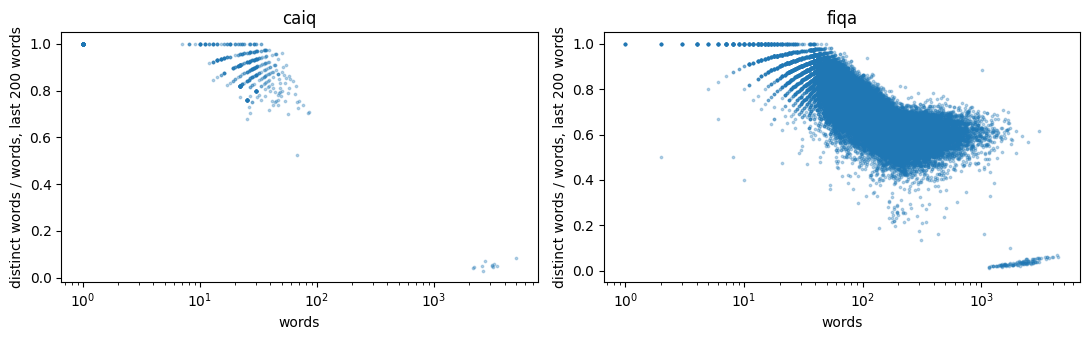

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
irrelevant = {}
for ax, ds in zip(axes, DATASETS):
    toks = [ladder.tokenize(t) for t in ds.texts]
    n = np.array([len(t) for t in toks])
    distinct = np.array([len(set(t[-200:])) / max(len(t[-200:]), 1) for t in toks])
    ax.scatter(n, distinct, s=3, alpha=0.3)
    ax.set_xscale("log")
    ax.set_xlabel("words")
    ax.set_ylabel("distinct words / words, last 200 words")
    ax.set_title(ds.name)
    irrelevant[ds.name] = {d for d, k, r in zip(ds.ids, n, distinct) if k > 200 and r < 0.09}
fig.tight_layout()

for ds in DATASETS:
    rows = [ds.row[d] for d in irrelevant[ds.name]]
    in_top = np.isin(ladder.topk(ds, TEXT[ds.name] + TITLE[ds.name]), rows).sum(1).mean()
    print(f"{ds.name}: {len(irrelevant[ds.name])} irrelevant documents, {in_top:.2f} of them in the top 10 per question")

## 5. Saturated BM25

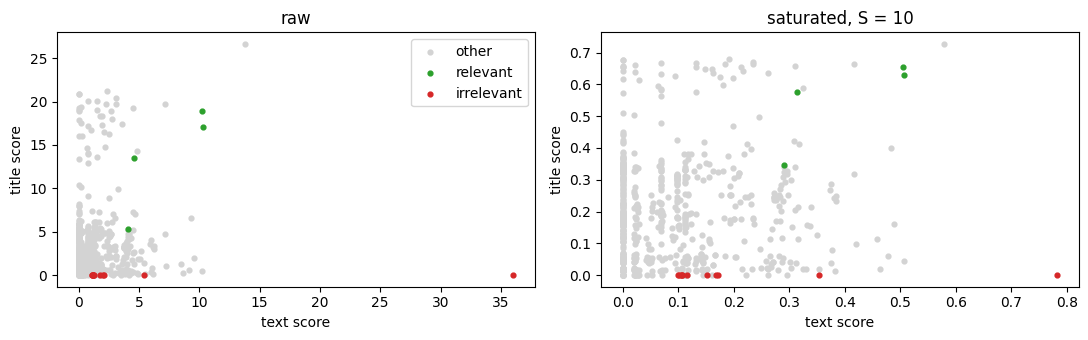

In [10]:
text, title = TEXT["caiq"][caiq.qrow[example]], TITLE["caiq"][caiq.qrow[example]]
is_irr = np.array([d in irrelevant["caiq"] for d in caiq.ids])
is_rel = np.array([caiq.qrels[example].get(d, 0) > 0 for d in caiq.ids])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (name, f) in zip(axes, (("raw", lambda x: x), ("saturated, S = 10", lambda x: x / (10 + x)))):
    for mask, label, color in ((~is_irr & ~is_rel, "other", "lightgrey"), (is_rel, "relevant", "C2"), (is_irr, "irrelevant", "C3")):
        ax.scatter(f(text[mask]), f(title[mask]), s=12, color=color, label=label)
    ax.set_xlabel("text score")
    ax.set_ylabel("title score")
    ax.set_title(name)
axes[0].legend()
fig.tight_layout()

{2: np.float64(0.463), 5: np.float64(0.472), 10: np.float64(0.491), 25: np.float64(0.524), 50: np.float64(0.528), 100: np.float64(0.525)}


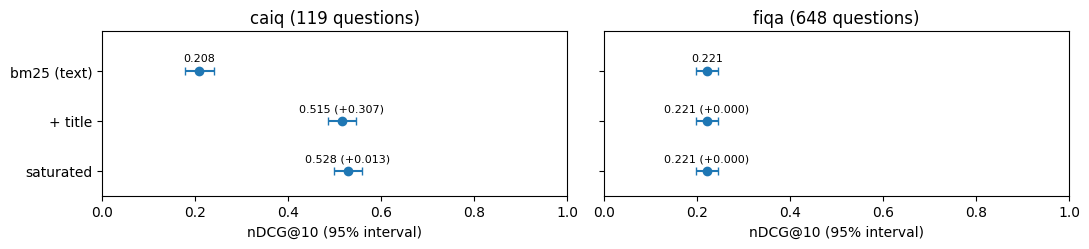

In [11]:
grid = {S: np.mean(list(ladder.evaluate(caiq, saturated(caiq, S)).values())) for S in (2, 5, 10, 25, 50, 100)}
print({S: round(v, 3) for S, v in grid.items()})
S = max(grid, key=grid.get)
for ds in DATASETS:
    runs[ds.name]["saturated"] = ladder.evaluate(ds, saturated(ds, S))
ladder.plot_ladder(runs);

In [12]:
ladder.show(caiq, example, {"+ title": TEXT["caiq"] + TITLE["caiq"], "saturated": saturated(caiq, S)})

q:present:LOG-01.1: For Present SpA: Are logging and monitoring policies and procedures established, documented, approved, communicated, applied, evaluated, and maintained?

+ title  nDCG@10 0.363
  1. [.] present:LOG-01.1 Present SpA — LOG-01.1: Are logging and monitoring policies and procedures established, do…
  2. [.] misc:007       Untitled Yes. Yes. Audit logs stored in PostgreSQL with database-level access controls. Ad…
  3. [1] present:GRC-01.1 Present SpA — GRC-01.1: Are information governance program policies and procedures sponsor…
  4. [1] fimil:LOG-01.1 Fimil — LOG-01.1: Are logging and monitoring policies and procedures established, document…
  5. [.] present:CEK-01.1 Present SpA — CEK-01.1: Are cryptography, encryption, and key management policies and proc…

saturated  nDCG@10 0.441
  1. [.] present:LOG-01.1 Present SpA — LOG-01.1: Are logging and monitoring policies and procedures established, do…
  2. [1] present:GRC-01.1 Present SpA — GRC-01.1: Are information governa

## 6. Phrase match

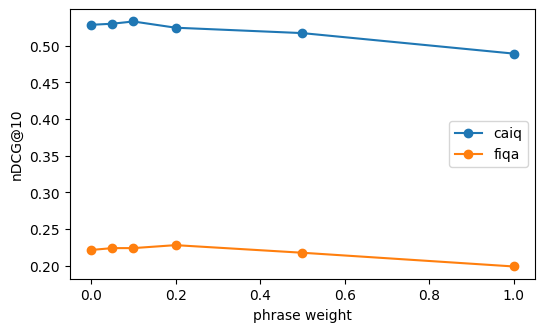

In [13]:
PHRASE_TEXT = {ds.name: ladder.phrase(ds, ds.texts) for ds in DATASETS}
PHRASE_TITLE = {ds.name: ladder.phrase(ds, ds.titles) for ds in DATASETS}
PHRASE = {n: 0.5 * PHRASE_TEXT[n] + PHRASE_TITLE[n] for n in PHRASE_TEXT}

def lexical(ds, w=0.2):
    return saturated(ds, S) + w * PHRASE[ds.name]

weights = (0, 0.05, 0.1, 0.2, 0.5, 1)
fig, ax = plt.subplots(figsize=(6, 3.5))
for ds in DATASETS:
    ax.plot(weights, [np.mean(list(ladder.evaluate(ds, lexical(ds, w)).values())) for w in weights], marker="o", label=ds.name)
ax.set_xlabel("phrase weight")
ax.set_ylabel("nDCG@10")
ax.legend()

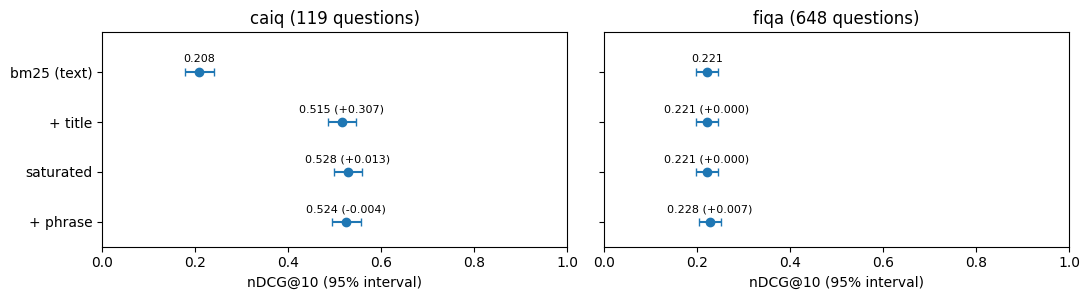

In [14]:
for ds in DATASETS:
    runs[ds.name]["+ phrase"] = ladder.evaluate(ds, lexical(ds))
ladder.plot_ladder(runs);

In [15]:
gain = {q: runs["fiqa"]["+ phrase"][q] - runs["fiqa"]["saturated"][q] for q in fiqa.qids}
example = max(gain, key=gain.get)
ladder.show(fiqa, example, {"saturated": saturated(fiqa, S), "+ phrase": lexical(fiqa)})

3528: In the US, does getting a loan with a cosigner, help your credit rating?



saturated  nDCG@10 0.387
  1. [.] 57211          "I am not sure how anyone is answering this unless they know what the loan was for. For in…
  2. [.] 142876         I am 17 and currently have a loan out for a car. My parents also have terrible credit, and…
  3. [.] 372993         "I had to apply for an American Express card, which was also rejected. Then I had searched…
  4. [.] 600048         &gt; hard to avoid. Unless, you know, you create a foreign corporation to do all your trad…
  5. [1] 345697         "It all comes down to how the loan itself is structured and reported - the exact details o…



+ phrase  nDCG@10 1.000
  1. [1] 345697         "It all comes down to how the loan itself is structured and reported - the exact details o…
  2. [.] 57211          "I am not sure how anyone is answering this unless they know what the loan was for. For in…
  3. [.] 372993         "I had to apply for an American Express card, which was also rejected. Then I had searched…
  4. [.] 205196         My son who is now 21 has never needed me to cosign on a loan for him and I did not need to…
  5. [.] 142876         I am 17 and currently have a loan out for a car. My parents also have terrible credit, and…



## 7. Learning to rank

In [16]:
import lightgbm as lgb

LEX_TOP = {ds.name: ladder.topk(ds, lexical(ds), 50) for ds in DATASETS}
FEATURES = ("bm25 text", "bm25 title", "phrase text", "phrase title")

def parts(ds):
    """The lexical formula's parts, as the formula uses them."""
    n = ds.name
    return [TEXT[n] / (S + TEXT[n]), TITLE[n] / (S + TITLE[n]), PHRASE_TEXT[n], PHRASE_TITLE[n]]

RAW = {ds.name: np.stack([np.take_along_axis(p, LEX_TOP[ds.name], 1) for p in parts(ds)], -1) for ds in DATASETS}
SCALE = {n: (x.mean((0, 1)), np.maximum(x.std((0, 1)), 1e-9)) for n, x in RAW.items()}
X = {n: (x - SCALE[n][0]) / SCALE[n][1] for n, x in RAW.items()}
Y = {ds.name: ladder.labels(ds, LEX_TOP[ds.name]) for ds in DATASETS}
GBM = dict(objective="lambdarank", learning_rate=0.05, num_leaves=7, deterministic=True, force_row_wise=True, verbose=-1)

def linear(x, y, ideal, x_test):
    return x_test @ ladder.lambdarank(x, y, ideal)

def lightgbm(x, y, ideal, x_test):
    model = lgb.train(GBM, lgb.Dataset(x.reshape(-1, x.shape[-1]), y.reshape(-1), group=[x.shape[1]] * len(x)), 200)
    return model.predict(x_test.reshape(-1, x.shape[-1])).reshape(x_test.shape[:2])

LTR = {fit.__name__: {ds.name: ladder.cross_validate(ds, X[ds.name], Y[ds.name], fit) for ds in DATASETS} for fit in (linear, lightgbm)}

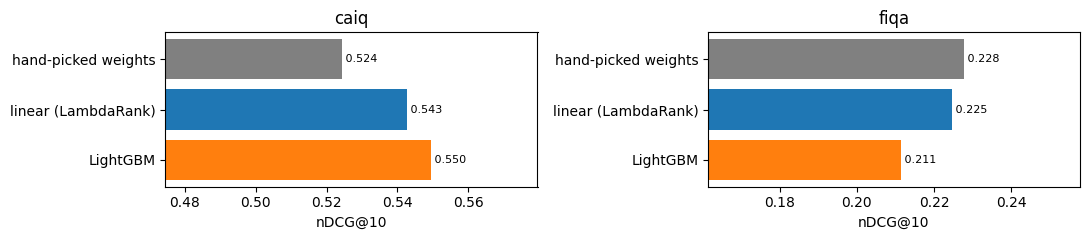

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 2.5))
for ax, ds in zip(axes, DATASETS):
    bars = {"hand-picked weights": np.take_along_axis(lexical(ds), LEX_TOP[ds.name], 1),
            "linear (LambdaRank)": LTR["linear"][ds.name], "LightGBM": LTR["lightgbm"][ds.name]}
    v = [np.mean(list(ladder.evaluate_top(ds, LEX_TOP[ds.name], s).values())) for s in bars.values()]
    ax.barh(list(bars), v, color=["grey", "C0", "C1"])
    for k, x in enumerate(v):
        ax.text(x, k, f" {x:.3f}", va="center", fontsize=8)
    ax.set_xlim(min(v) - 0.05, max(v) + 0.03)
    ax.invert_yaxis()
    ax.set_title(ds.name)
    ax.set_xlabel("nDCG@10")
fig.tight_layout()

In [18]:
for ds in DATASETS:
    w = ladder.lambdarank(X[ds.name], Y[ds.name], ladder.ideal_dcg(ds)) / SCALE[ds.name][1]  # weights on the formula's own parts
    w = w / w.max()
    print(f"{ds.name}: score = " + " + ".join(f"{v:.2f} · {f}" for f, v in zip(FEATURES, w) if v > 1e-3))

print(f"\n{'':16s}" + "".join(f"{ds.name + ' gain':>12s}{ds.name + ' drop-one':>16s}" for ds in DATASETS))
importance = {}
for ds in DATASETS:
    booster = lgb.train(GBM, lgb.Dataset(X[ds.name].reshape(-1, len(FEATURES)), Y[ds.name].reshape(-1), group=[50] * len(ds.qids)), 200)
    gain = booster.feature_importance("gain") / max(booster.feature_importance("gain").sum(), 1e-9)
    full = np.mean(list(ladder.evaluate_top(ds, LEX_TOP[ds.name], LTR["linear"][ds.name]).values()))
    for i, f in enumerate(FEATURES):
        rest = ladder.cross_validate(ds, np.delete(X[ds.name], i, -1), Y[ds.name], linear)
        importance[ds.name, f] = (gain[i], np.mean(list(ladder.evaluate_top(ds, LEX_TOP[ds.name], rest).values())) - full)
for f in FEATURES:
    print(f"{f:16s}" + "".join(f"{importance[ds.name, f][0]:12.0%}{importance[ds.name, f][1]:+16.3f}" for ds in DATASETS))

caiq: score = 0.51 · bm25 text + 1.00 · bm25 title


fiqa: score = 1.00 · bm25 text + 0.07 · phrase text

                   caiq gain   caiq drop-one   fiqa gain   fiqa drop-one


bm25 text                25%          -0.057         83%          -0.061
bm25 title               66%          -0.083          0%          +0.000
phrase text               2%          +0.000         17%          -0.004
phrase title              8%          +0.000          0%          +0.000


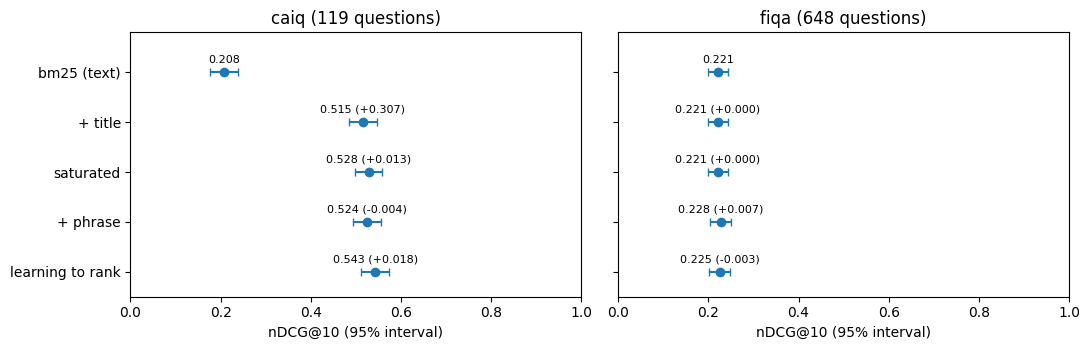

In [19]:
for ds in DATASETS:
    runs[ds.name]["learning to rank"] = ladder.evaluate_top(ds, LEX_TOP[ds.name], LTR["linear"][ds.name])
ladder.plot_ladder(runs);

In [20]:
gain = {q: runs["caiq"]["learning to rank"][q] - runs["caiq"]["+ phrase"][q] for q in caiq.qids}
example = max(gain, key=gain.get)
ladder.show(caiq, example, {"+ phrase": lexical(caiq), "learning to rank": ladder.expand(caiq, LEX_TOP["caiq"], LTR["linear"]["caiq"])})

q:fimil:LOG-06.1: For Fimil: Is a reliable time source being used across all relevant systems?

+ phrase  nDCG@10 0.307
  1. [.] fimil:LOG-06.1 Fimil — LOG-06.1: Is a reliable time source being used across all relevant systems? Yes. A…
  2. [.] misc:002       Untitled Yes. Incident Response Plan defines customer notification procedures for data bre…
  3. [1] present:LOG-06.1 Present SpA — LOG-06.1: Is a reliable time source being used across all relevant informati…
  4. [.] realigned:TVM-02.5 Realigned Technologies — TVM-02.5: Do you have a capability to patch vulnerabilities acros…
  5. [.] octopus:TVM-01.1 Octopus Deploy — TVM-01.1: Do you have anti-malware programs that support or connect to yo…

learning to rank  nDCG@10 0.832
  1. [1] present:LOG-06.1 Present SpA — LOG-06.1: Is a reliable time source being used across all relevant informati…
  2. [.] misc:002       Untitled Yes. Incident Response Plan defines customer notification procedures for data bre…
  3. [.] realigned:TVM-02

## 8. Dense embeddings

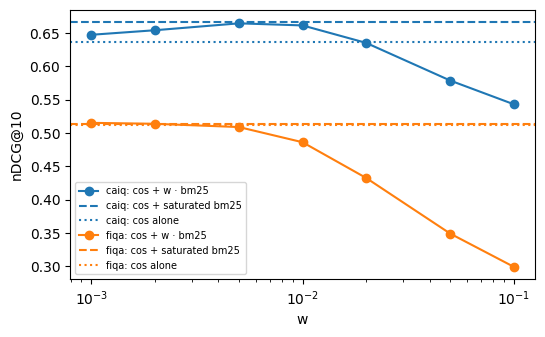

In [21]:
VEC = {ds.name: ladder.vectors(ds) for ds in DATASETS}
COS = {name: q @ d.T for name, (d, q) in VEC.items()}
dense = {ds.name: ladder.evaluate(ds, COS[ds.name]) for ds in DATASETS}

def naive(ds, w):
    return COS[ds.name] + w * (TEXT[ds.name] + TITLE[ds.name])

def hybrid(ds):
    return 4 * np.maximum(0, COS[ds.name] - 0.05) + lexical(ds)

weights = (0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1)
fig, ax = plt.subplots(figsize=(6, 3.5))
for ds in DATASETS:
    curve = [np.mean(list(ladder.evaluate(ds, naive(ds, w)).values())) for w in weights]
    ax.plot(weights, curve, marker="o", label=f"{ds.name}: cos + w · bm25")
    color = ax.lines[-1].get_color()
    ax.axhline(np.mean(list(ladder.evaluate(ds, hybrid(ds)).values())), ls="--", color=color, label=f"{ds.name}: cos + saturated bm25")
    ax.axhline(np.mean(list(dense[ds.name].values())), ls=":", color=color, label=f"{ds.name}: cos alone")
ax.set_xscale("log")
ax.set_xlabel("w")
ax.set_ylabel("nDCG@10")
ax.legend(fontsize=7)

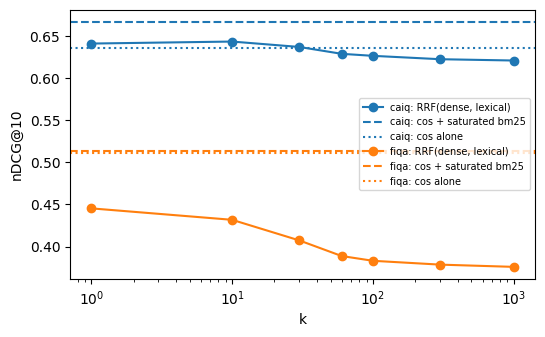

In [22]:
def rrf(k, *scores):
    """Reciprocal rank fusion: each list adds 1 / (k + rank) for every document; the scores themselves are dropped."""
    return sum(1 / (k + np.argsort(np.argsort(-s, axis=1), axis=1) + 1) for s in scores)

ks = (1, 10, 30, 60, 100, 300, 1000)
fig, ax = plt.subplots(figsize=(6, 3.5))
for ds in DATASETS:
    ax.plot(ks, [np.mean(list(ladder.evaluate(ds, rrf(k, COS[ds.name], lexical(ds))).values())) for k in ks], marker="o",
            label=f"{ds.name}: RRF(dense, lexical)")
    color = ax.lines[-1].get_color()
    ax.axhline(np.mean(list(ladder.evaluate(ds, hybrid(ds)).values())), ls="--", color=color, label=f"{ds.name}: cos + saturated bm25")
    ax.axhline(np.mean(list(dense[ds.name].values())), ls=":", color=color, label=f"{ds.name}: cos alone")
ax.set_xscale("log")
ax.set_xlabel("k")
ax.set_ylabel("nDCG@10")
ax.legend(fontsize=7)

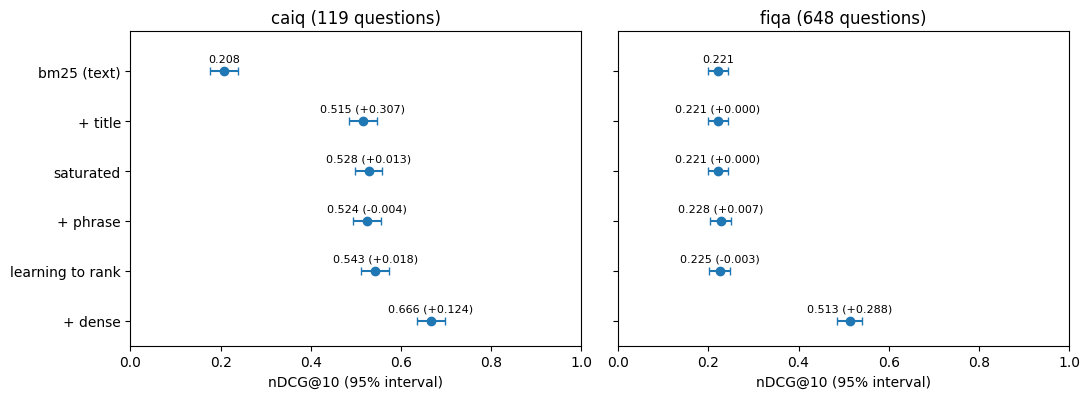

In [23]:
for ds in DATASETS:
    runs[ds.name]["+ dense"] = ladder.evaluate(ds, hybrid(ds))
ladder.plot_ladder(runs);

In [24]:
gain = {q: runs["fiqa"]["+ dense"][q] - runs["fiqa"]["+ phrase"][q] for q in fiqa.qids}
example = max(gain, key=gain.get)
ladder.show(fiqa, example, {"+ phrase": lexical(fiqa), "+ dense": hybrid(fiqa)})

15: Can I send a money order from USPS as a business?



+ phrase  nDCG@10 0.000
  1. [.] 420483         On your end of the deal, the biggest risk is probably counterfeiting. That said, I'd think…
  2. [.] 230003         "&gt; ""So I'll either stop shipping prescriptions or switch to FedEx or UPS -- which cost…
  3. [.] 224000         "A money order is basically a pre-paid check. The physical cash would probably get deposit…
  4. [.] 454734         The net benefit to the US economy for the DoD is likely positive thanks to the Navy alone,…
  5. [.] 28974          "I agree with the rest of the answers -- you're probably better off just using it for some…



+ dense  nDCG@10 1.000
  1. [1] 325273         Sure you can. You can fill in whatever you want in the From section of a money order, so y…
  2. [.] 224000         "A money order is basically a pre-paid check. The physical cash would probably get deposit…
  3. [.] 420483         On your end of the deal, the biggest risk is probably counterfeiting. That said, I'd think…
  4. [.] 284528         The US Postal Service to my recollection recommends only mailing cash or items with cash-l…
  5. [.] 233145         I assume you kept the receipt for your money order, in which case there's no reason you ca…



## 9. Long documents

In [25]:
VEC512 = {ds.name: ladder.vectors(ds, window=512) for ds in DATASETS}
COS512 = {name: q @ d.T for name, (d, q) in VEC512.items()}
for ds in DATASETS:
    long = (VEC512[ds.name][0] != VEC[ds.name][0]).any(1)
    rel = [ds.row[d] for q in ds.qids for d, g in ds.qrels[q].items() if g > 0 and d in ds.row]
    irr = np.array([d in irrelevant[ds.name] for d in ds.ids])
    print(f"{ds.name}: {long.sum():,} documents longer than 512 tokens ({long.mean():.1%}); "
          f"{long[rel].mean():.1%} of relevant documents, {long[irr].mean():.0%} of irrelevant ones")

caiq: 11 documents longer than 512 tokens (1.7%); 0.0% of relevant documents, 100% of irrelevant ones
fiqa: 2,435 documents longer than 512 tokens (4.2%); 7.8% of relevant documents, 100% of irrelevant ones


caiq, window 512 tokens: an irrelevant document in the dense top 10 for 19% of questions
caiq, window whole document: an irrelevant document in the dense top 10 for 15% of questions


fiqa, window 512 tokens: an irrelevant document in the dense top 10 for 1% of questions


fiqa, window whole document: an irrelevant document in the dense top 10 for 8% of questions


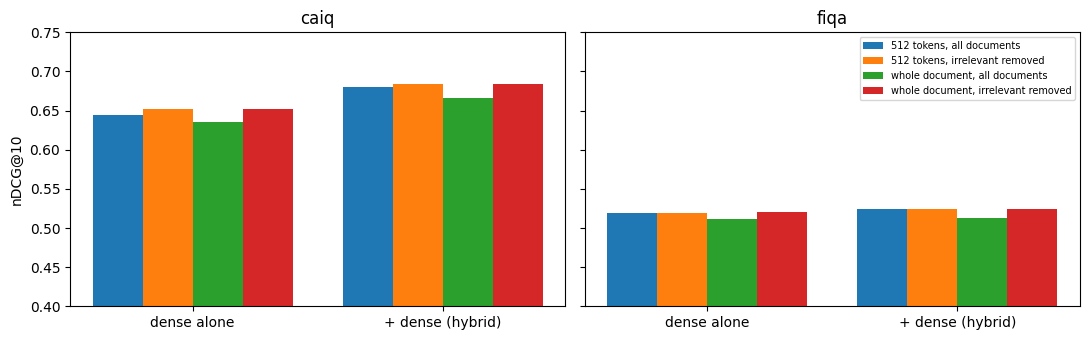

In [26]:
def with_cos(ds, cos):
    return 4 * np.maximum(0, cos - 0.05) + lexical(ds)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, ds in zip(axes, DATASETS):
    keep = np.array([d not in irrelevant[ds.name] for d in ds.ids])
    bars = {}
    for window, cos in (("512 tokens", COS512[ds.name]), ("whole document", COS[ds.name])):
        for docs, mask in (("all documents", np.ones_like(keep)), ("irrelevant removed", keep)):
            bars[f"{window}, {docs}"] = [np.mean(list(ladder.evaluate(ds, np.where(mask, s, -np.inf)).values()))
                                         for s in (cos, with_cos(ds, cos))]
        top = ladder.topk(ds, cos, 10)
        print(f"{ds.name}, window {window}: an irrelevant document in the dense top 10 for "
              f"{(~keep)[top].any(1).mean():.0%} of questions")
    for k, (label, v) in enumerate(bars.items()):
        ax.bar(np.arange(2) + k * 0.2 - 0.3, v, 0.2, label=label)
    ax.set_xticks(range(2), ["dense alone", "+ dense (hybrid)"])
    ax.set_ylim(0.4, 0.75)
    ax.set_title(ds.name)
axes[0].set_ylabel("nDCG@10")
axes[1].legend(fontsize=7)
fig.tight_layout()

In [27]:
keep = np.array([d not in irrelevant["fiqa"] for d in fiqa.ids])
top512, top = ladder.topk(fiqa, COS512["fiqa"], 10), ladder.topk(fiqa, COS["fiqa"], 10)
climbed = [q for r, q in enumerate(fiqa.qids) if (~keep)[top[r]].any() and not (~keep)[top512[r]].any()]
ladder.show(fiqa, climbed[0], {"512 tokens": COS512["fiqa"], "whole document": COS["fiqa"]})

549: Where to request ACH Direct DEBIT of funds from MY OWN personal bank account?



512 tokens  nDCG@10 1.000
  1. [1] 214024         Call Wells Fargo or go to a branch. Tell them what you're trying to accomplish, not the ve…
  2. [.] 221061         "Generally, ACH transfers are not considered direct deposits. However, you can pay for thi…
  3. [.] 595633         Typically, a direct debit is set up by the company who will be receiving the money, not by…
  4. [.] 240328         The RDFI (Receiving Depository Institution) is the place where you keep your money and whe…
  5. [.] 190537         I had a similar situation a while ago, and here's what I learned: What are our options her…



whole document  nDCG@10 0.631
  1. [.] 600049         A special 24/7 available QuickBooks support phone number helpline for users who are gettin…
  2. [1] 214024         Call Wells Fargo or go to a branch. Tell them what you're trying to accomplish, not the ve…
  3. [.] 221061         "Generally, ACH transfers are not considered direct deposits. However, you can pay for thi…
  4. [.] 595633         Typically, a direct debit is set up by the company who will be receiving the money, not by…
  5. [.] 240328         The RDFI (Receiving Depository Institution) is the place where you keep your money and whe…



## 10. Binary embeddings

In [28]:
def signs(x):
    return np.where(x >= 0, 1, -1).astype(np.float32)

BIN, CENTERED, ASYM = {}, {}, {}
for ds in DATASETS:
    d, q = VEC[ds.name]
    mean = d.mean(0)
    BIN[ds.name] = signs(q) @ signs(d).T
    CENTERED[ds.name] = signs(q - mean) @ signs(d - mean).T
    ASYM[ds.name] = (q - mean) @ signs(d - mean).T / np.sqrt(d.shape[1])  # the question stays float; documents are bits
    print(f"{ds.name}: {d.nbytes / 1e6:.1f} MB as float32, {np.packbits(d >= 0, axis=1).nbytes / 1e6:.2f} MB as bits; "
          f"nDCG@10 float {np.mean(list(dense[ds.name].values())):.3f}, "
          f"bits {np.mean(list(ladder.evaluate(ds, BIN[ds.name]).values())):.3f}, "
          f"centered bits {np.mean(list(ladder.evaluate(ds, CENTERED[ds.name]).values())):.3f}, "
          f"float question × centered bits {np.mean(list(ladder.evaluate(ds, ASYM[ds.name]).values())):.3f}")

caiq: 2.6 MB as float32, 0.08 MB as bits; nDCG@10 float 0.636, bits 0.598, centered bits 0.608, float question × centered bits 0.618


fiqa: 237.2 MB as float32, 7.41 MB as bits; nDCG@10 float 0.511, bits 0.483, centered bits 0.485, float question × centered bits 0.503


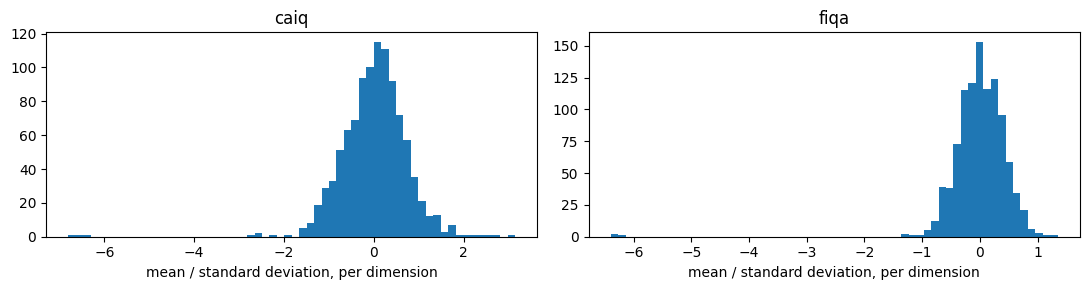

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, ds in zip(axes, DATASETS):
    d, _ = VEC[ds.name]
    ax.hist(d.mean(0) / d.std(0), bins=60)
    ax.set_title(ds.name)
    ax.set_xlabel("mean / standard deviation, per dimension")
fig.tight_layout()

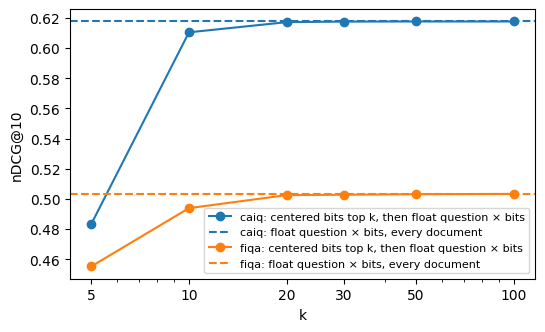

In [30]:
windows = (5, 10, 20, 30, 50, 100)
fig, ax = plt.subplots(figsize=(6, 3.5))
for ds in DATASETS:
    curve = [np.mean(list(ladder.evaluate(ds, ladder.rescore(ds, CENTERED[ds.name], ASYM[ds.name], k)).values())) for k in windows]
    ax.plot(windows, curve, marker="o", label=f"{ds.name}: centered bits top k, then float question × bits")
    ax.axhline(np.mean(list(ladder.evaluate(ds, ASYM[ds.name]).values())), ls="--", color=ax.lines[-1].get_color(),
               label=f"{ds.name}: float question × bits, every document")
ax.set_xscale("log")
ax.set_xticks(windows, windows)
ax.set_xlabel("k")
ax.set_ylabel("nDCG@10")
ax.legend(fontsize=8)

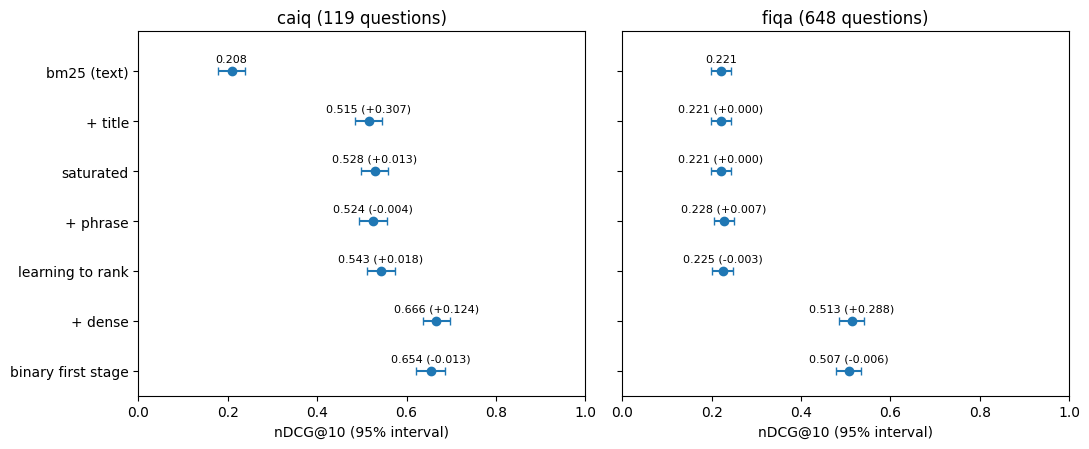

In [31]:
def hybrid_bits(ds):
    return 4 * np.maximum(0, ASYM[ds.name]) + lexical(ds)

CAND = {ds.name: ladder.candidates(ds, [CENTERED[ds.name], TEXT[ds.name] + TITLE[ds.name]], 20) for ds in DATASETS}
for ds in DATASETS:
    runs[ds.name]["binary first stage"] = ladder.evaluate(ds, np.where(CAND[ds.name], hybrid_bits(ds), -np.inf))
ladder.plot_ladder(runs);

## 11. Late interaction

Late interaction (ColBERT) keeps one vector per token and matches each question token to its best document token. Its value depends on the model and dataset: LateOn improves FiQA, but contributes almost nothing on CAIQ. This section compares three precomputed models with Perplexity's new v2 0.6B model.

In [32]:
STEP5 = {ds.name: np.where(CAND[ds.name], hybrid_bits(ds), -np.inf) for ds in DATASETS}
TOP20 = {ds.name: ladder.topk(ds, STEP5[ds.name], 20) for ds in DATASETS}

def at(ds, scores):
    return np.take_along_axis(scores, TOP20[ds.name], 1)

def minmax(x):
    lo, hi = x.min(1, keepdims=True), x.max(1, keepdims=True)
    return (x - lo) / np.maximum(hi - lo, 1e-9)

TOK = {ds.name: ladder.late_tokens(ds, ENCODE_ON_GPU) for ds in DATASETS}
d_bytes = 1024 * 2
for ds in DATASETS:
    n = np.diff(TOK[ds.name].start).mean()
    print(f"{ds.name}: dense, one vector per document: {d_bytes:,} bytes as float16, {d_bytes // 16:,} as bits; pplx v2-late, "
          f"{n:.0f} vectors of 128 per document: {n * 256:,.0f} bytes as float16, {n * 128:,.0f} as int8, {n * 16:,.0f} as bits")

caiq: dense, one vector per document: 2,048 bytes as float16, 128 as bits; pplx v2-late, 107 vectors of 128 per document: 27,379 bytes as float16, 13,689 as int8, 1,711 as bits
fiqa: dense, one vector per document: 2,048 bytes as float16, 128 as bits; pplx v2-late, 163 vectors of 128 per document: 41,622 bytes as float16, 20,811 as int8, 2,601 as bits


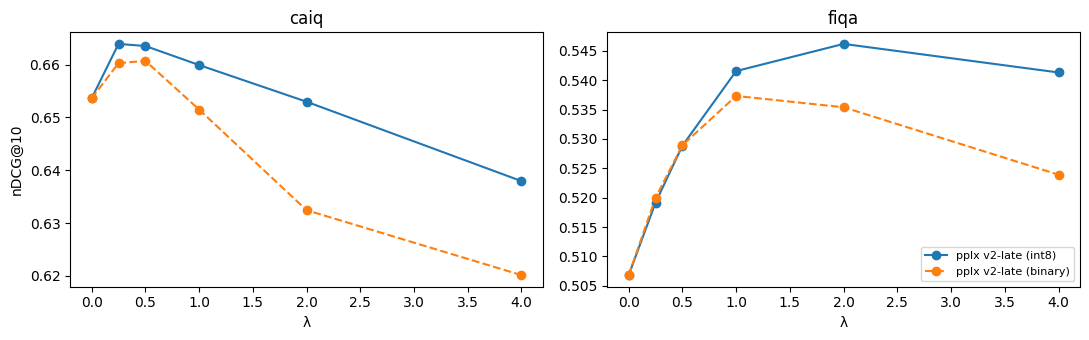

In [33]:
LATE = {form: {ds.name: ladder.maxsim(ds, TOK[ds.name], TOP20[ds.name], binary=form == "binary") for ds in DATASETS}
        for form in ("int8", "binary")}

def fused(ds, scores, lam):
    return minmax(at(ds, STEP5[ds.name])) + lam * minmax(scores)

lams = (0, 0.25, 0.5, 1, 2, 4)
CURVE = {(form, ds.name): [np.mean(list(ladder.evaluate_top(ds, TOP20[ds.name], fused(ds, LATE[form][ds.name], lam)).values()))
                           for lam in lams] for form in LATE for ds in DATASETS}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, ds in zip(axes, DATASETS):
    for form, ls in (("int8", "-"), ("binary", "--")):
        ax.plot(lams, CURVE[form, ds.name], ls=ls, marker="o", label=f"pplx v2-late ({form})")
    ax.set_title(ds.name)
    ax.set_xlabel("λ")
axes[0].set_ylabel("nDCG@10")
axes[1].legend(fontsize=8)
fig.tight_layout()

In [34]:
for ds in DATASETS:
    alone = {"step 5": at(ds, STEP5[ds.name]), **{f"pplx v2-late ({form})": LATE[form][ds.name] for form in LATE}}
    print(f"{ds.name}, the same top 20 ordered by " + ", ".join(
        f"{name} {np.mean(list(ladder.evaluate_top(ds, TOP20[ds.name], s).values())):.3f}" for name, s in alone.items()))

caiq, the same top 20 ordered by step 5 0.654, pplx v2-late (int8) 0.613, pplx v2-late (binary) 0.603
fiqa, the same top 20 ordered by step 5 0.507, pplx v2-late (int8) 0.531, pplx v2-late (binary) 0.501


{'caiq': 0.5, 'fiqa': 1}


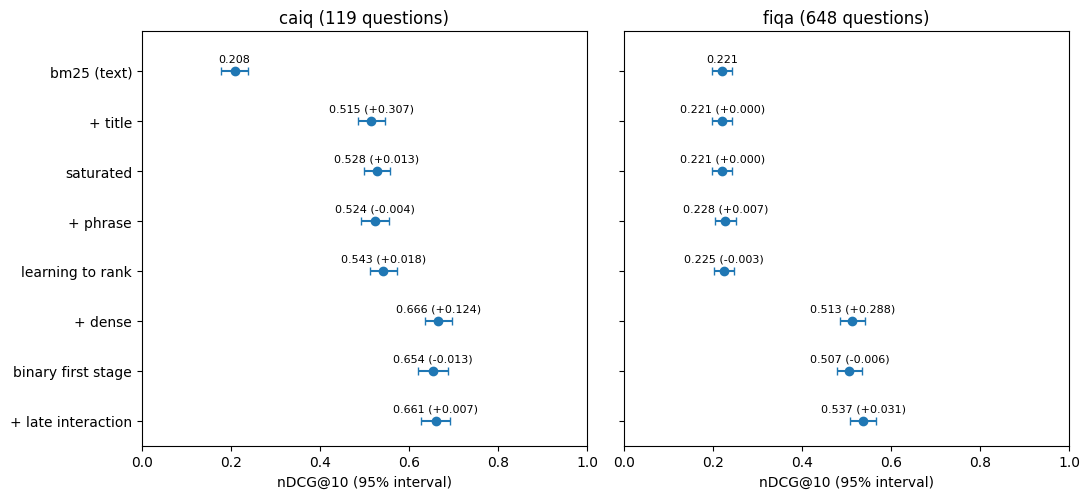

In [35]:
LAM_LATE = {ds.name: lams[int(np.argmax(CURVE["binary", ds.name]))] for ds in DATASETS}  # read off the curves above
print(LAM_LATE)
for ds in DATASETS:
    runs[ds.name]["+ late interaction"] = ladder.evaluate_top(ds, TOP20[ds.name], fused(ds, LATE["binary"][ds.name], LAM_LATE[ds.name]))
ladder.plot_ladder(runs);

In [36]:
for ds in DATASETS:
    n = np.diff(TOK[ds.name].start).mean()
    size = {"int8": n * 128, "binary": n * 16}
    print(f"{ds.name}: " + ", ".join(f"{form} {max(CURVE[form, ds.name]):.3f} ({size[form]:,.0f} bytes per document)" for form in LATE))

caiq: int8 0.664 (13,689 bytes per document), binary 0.661 (1,711 bytes per document)
fiqa: int8 0.546 (20,811 bytes per document), binary 0.537 (2,601 bytes per document)


## 12. Cross-encoder

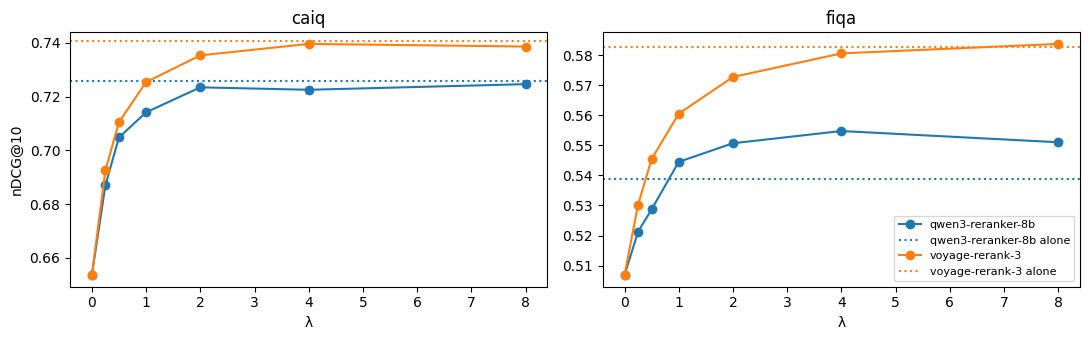

In [37]:
MODELS = ("qwen3-reranker-8b", "voyage-rerank-3")
CE = {m: {ds.name: ladder.rerank(ds, TOP20[ds.name], m) for ds in DATASETS} for m in MODELS}

def reranked(ds, lam, model):
    return minmax(at(ds, STEP5[ds.name])) + lam * minmax(CE[model][ds.name])

lams = (0, 0.25, 0.5, 1, 2, 4, 8)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, ds in zip(axes, DATASETS):
    for m in MODELS:
        ax.plot(lams, [np.mean(list(ladder.evaluate_top(ds, TOP20[ds.name], reranked(ds, lam, m)).values())) for lam in lams],
                marker="o", label=m)
        ax.axhline(np.mean(list(ladder.evaluate_top(ds, TOP20[ds.name], CE[m][ds.name]).values())), ls=":",
                   color=ax.lines[-1].get_color(), label=f"{m} alone")
    ax.set_title(ds.name)
    ax.set_xlabel("λ")
axes[0].set_ylabel("nDCG@10")
axes[1].legend(fontsize=8)
fig.tight_layout()

{'caiq': 4, 'fiqa': 8}


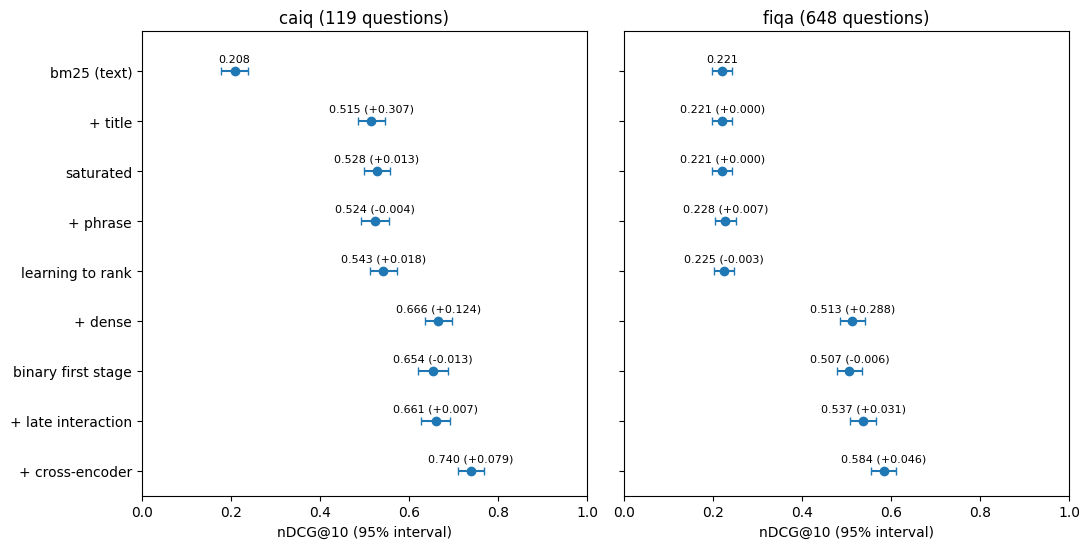

In [38]:
LAM_CE = {ds.name: max(lams, key=lambda lam: np.mean(list(ladder.evaluate_top(ds, TOP20[ds.name], reranked(ds, lam, "voyage-rerank-3")).values())))
          for ds in DATASETS}  # read off the curves above
print(LAM_CE)
for ds in DATASETS:
    runs[ds.name]["+ cross-encoder"] = ladder.evaluate_top(ds, TOP20[ds.name], reranked(ds, LAM_CE[ds.name], "voyage-rerank-3"))
ladder.plot_ladder(runs);

In [39]:
gain = {q: runs["caiq"]["+ cross-encoder"][q] - runs["caiq"]["binary first stage"][q] for q in caiq.qids}
example = max(gain, key=gain.get)
ladder.show(caiq, example, {"binary first stage": STEP5["caiq"],
                            "+ cross-encoder": ladder.expand(caiq, TOP20["caiq"], reranked(caiq, LAM_CE["caiq"], "voyage-rerank-3"))})

q:realigned:DCS-01.2: For Realigned Technologies: Do you maintain a complete inventory of all of your critical assets located at all sites/ or geographical locations and their assigned ownership?

binary first stage  nDCG@10 0.452
  1. [1] octopus:DCS-01.2 Octopus Deploy — DCS-01.2: Do you maintain a complete inventory of all of your critical as…
  2. [.] realigned:BCR-11.3 Realigned Technologies — BCR-11.3: Have you implemented backup or recovery mechanisms to e…
  3. [.] realigned:BCR-11.7 Realigned Technologies — BCR-11.7: Do you test your backup or redundancy mechanisms at lea…
  4. [.] realigned:BCR-11.1 Realigned Technologies — BCR-11.1: Do you have technical capabilities to enforce tenant da…
  5. [.] realigned:IAM-04.1 Realigned Technologies — IAM-04.1: Do you manage and store the identity of all personnel w…

+ cross-encoder  nDCG@10 0.952
  1. [1] octopus:DCS-01.2 Octopus Deploy — DCS-01.2: Do you maintain a complete inventory of all of your critical as…
  2. [1] present:DCS-

## 13. How sure are we?

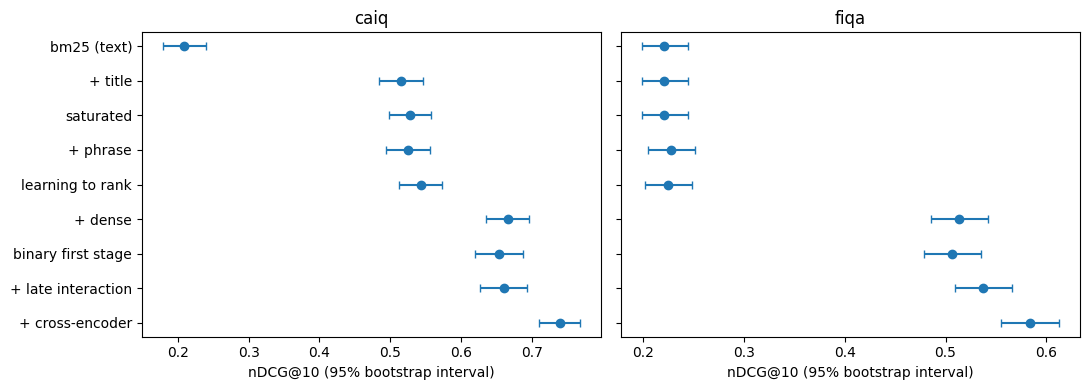

In [40]:
PER_Q = {ds.name: {step: np.array([r[q] for q in ds.qids]) for step, r in runs[ds.name].items()} for ds in DATASETS}
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, ds in zip(axes, DATASETS):
    steps = list(PER_Q[ds.name])
    for i, step in enumerate(steps):
        x = PER_Q[ds.name][step]
        lo, hi = ladder.bootstrap(x)
        ax.errorbar(x.mean(), i, xerr=[[x.mean() - lo], [hi - x.mean()]], fmt="o", color="C0", capsize=3)
    ax.set_yticks(range(len(steps)), steps)
    ax.set_title(ds.name)
    ax.set_xlabel("nDCG@10 (95% bootstrap interval)")
axes[0].invert_yaxis()
fig.tight_layout()

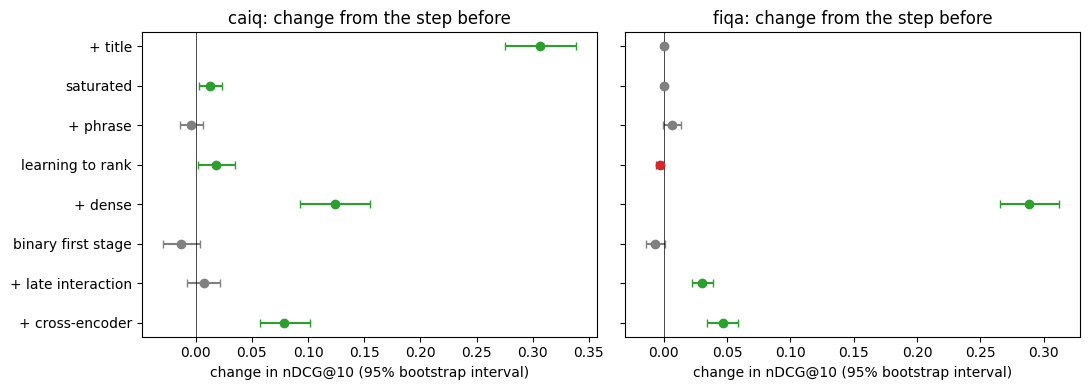

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, ds in zip(axes, DATASETS):
    steps = list(PER_Q[ds.name])
    for i, (before, step) in enumerate(zip(steps, steps[1:])):
        d = PER_Q[ds.name][step] - PER_Q[ds.name][before]  # the same questions, before and after
        lo, hi = ladder.bootstrap(d)
        color = "C2" if lo > 0 else "C3" if hi < 0 else "grey"
        ax.errorbar(d.mean(), i, xerr=[[d.mean() - lo], [hi - d.mean()]], fmt="o", color=color, capsize=3)
    ax.axvline(0, color="black", lw=0.5)
    ax.set_yticks(range(len(steps) - 1), steps[1:])
    ax.set_title(f"{ds.name}: change from the step before")
    ax.set_xlabel("change in nDCG@10 (95% bootstrap interval)")
axes[0].invert_yaxis()
fig.tight_layout()

## 14. Debugging failing questions

In [42]:
FINAL = {ds.name: reranked(ds, LAM_CE[ds.name], "voyage-rerank-3") for ds in DATASETS}

for ds in DATASETS:
    print(f"{ds.name}: the 10 questions the final ranking does worst on")
    for q in sorted(ds.qids, key=lambda q: runs[ds.name]["+ cross-encoder"][q])[:10]:
        r = ds.qrow[q]
        cand = TOP20[ds.name][r]
        first = [k for k, i in enumerate(cand[np.argsort(-FINAL[ds.name][r], kind="stable")], 1) if ds.qrels[q].get(ds.ids[i], 0) > 0]
        verdict = f"first relevant at {first[0]} of 20" if first else "no relevant document among the 20 candidates"
        print(f"  {runs[ds.name]['+ cross-encoder'][q]:.2f}  {verdict:46s} {ds.queries[q][:80]}")

caiq: the 10 questions the final ranking does worst on
  0.00  no relevant document among the 20 candidates   For Octopus Deploy: Do you publish a list of all APIs available in the service a
  0.25  first relevant at 2 of 20                      For Realigned Technologies: Are your information security policies and procedure
  0.36  first relevant at 2 of 20                      For Realigned Technologies: Are all identified security, contractual, and regula
  0.40  first relevant at 3 of 20                      For Octopus Deploy: Are personnel trained and provided with awareness programs a
  0.44  first relevant at 1 of 20                      For Fimil: Are applications and infrastructures designed to appropriately segmen
  0.47  first relevant at 1 of 20                      For Present SpA: Are policies and procedures established, documented, approved, 
  0.51  first relevant at 1 of 20                      For Present SpA: Are processes, procedures, and technical measures for sec

In [43]:
worst = min(caiq.qids, key=lambda q: runs["caiq"]["+ cross-encoder"][q])
ladder.show(caiq, worst, {"binary first stage": STEP5["caiq"], "+ cross-encoder": ladder.expand(caiq, TOP20["caiq"], FINAL["caiq"])})

q:octopus:IPY-01.1: For Octopus Deploy: Do you publish a list of all APIs available in the service and indicate which are standard and which are customized?

binary first stage  nDCG@10 0.000
  1. [.] octopus:STA-07.4 Octopus Deploy — STA-07.4: Do you provide tenants with ongoing visibility and reporting of…
  2. [.] octopus:STA-02.1 Octopus Deploy — STA-02.1: Do you make security incident information available to all affe…
  3. [.] octopus:BCR-10.1 Octopus Deploy — BCR-10.1: Are policies and procedures established and made available for …
  4. [.] octopus:DCS-01.2 Octopus Deploy — DCS-01.2: Do you maintain a complete inventory of all of your critical as…
  5. [.] octopus:STA-03.1 Octopus Deploy — STA-03.1: Do you collect capacity and use data for all relevant component…

+ cross-encoder  nDCG@10 0.000
  1. [.] octopus:BCR-10.1 Octopus Deploy — BCR-10.1: Are policies and procedures established and made available for …
  2. [.] octopus:STA-02.1 Octopus Deploy — STA-02.1: Do you make sec

## 15. Leaderboard

In [44]:
import json, re, urllib.error, urllib.request
from concurrent.futures import ThreadPoolExecutor

LAB = json.load(open(".lab.json"))  # written by: python3 ladder.py connect URL TOKEN

def post(url, key, body):
    req = urllib.request.Request(url, json.dumps(body).encode(),
                                 {"Authorization": f"Bearer {key}", "Content-Type": "application/json"})
    try:
        with urllib.request.urlopen(req, timeout=120) as r:
            return json.load(r)
    except urllib.error.HTTPError as e:
        raise RuntimeError(f"{e.code}: {e.read().decode(errors='replace')}") from None

def embed(text):
    """The question's pplx vector from the lab: it must match the documents' vectors."""
    r = post(f"{LAB['url']}/v1/embeddings", LAB["token"], dict(model="pplx-embed", input=[text]))
    return np.array(r["data"][0]["embedding"], dtype=np.float32)[None]

In [45]:
DOC_BITS = {name: (d.mean(0), signs(d - d.mean(0))) for name, (d, _) in VEC.items()}

def search(ds, query, qid=None, k=5):
    """The ladder for one new question: lexical + dense over the binary candidates, then Voyage on the top 20.
    qid hides what that question hides (its own answer)."""
    one = ladder.single(ds, query, qid)
    text, title = ladder.bm25(one, ds.texts, idf_texts=ds.title_text), ladder.bm25(one, ds.titles, idf_texts=ds.title_text)
    lexical = text / (S + text) + title / (S + title) + 0.2 * (0.5 * ladder.phrase(one, ds.texts) + ladder.phrase(one, ds.titles))
    q = embed(query)
    mean, bits = DOC_BITS[ds.name]
    cand = ladder.candidates(one, [signs(q - mean) @ bits.T, text + title], 20)
    step5 = np.where(cand, 4 * np.maximum(0, (q - mean) @ bits.T / np.sqrt(bits.shape[1])) + lexical, -np.inf)
    top = ladder.topk(one, step5, 20)
    fused = minmax(np.take_along_axis(step5, top, 1)) + 4 * minmax(ladder.rerank(one, top, "voyage-rerank-3"))
    return top[0][np.argsort(-fused[0])][:k]

def bm25_search(ds, query, qid=None, k=5):
    """The ladder's first step: BM25 over the text only."""
    one = ladder.single(ds, query, qid)
    return ladder.topk(one, ladder.bm25(one, ds.texts), k)[0]

def hits(ds, rows):
    return "\n".join(f"{n}. [doc:{ds.ids[i]}] {ds.titles[i]}\n   {ds.texts[i][:300]}" for n, i in enumerate(rows, 1))

def read(ds, doc_id):
    i = ds.row.get(doc_id)
    return f"[doc:{doc_id}] {ds.titles[i]}\n{ds.texts[i][:4000]}" if i is not None else f"no document {doc_id}"

In [44]:
for label, fn in (("bm25", bm25_search), ("the ladder", search)):
    print(label, ladder.submit(fiqa, fn, label))

bm25 {'score': 0.0551, 'best': 0.0551, 'rank': 1, 'of': 1}


the ladder {'score': 0.5156, 'best': 0.5156, 'rank': 1, 'of': 1}


## 16. A RAG agent from scratch

In [46]:
BASE_URL, API_KEY, MODEL = LAB["url"] + "/v1", LAB["token"], "claude-haiku-5-5"  # or any OpenAI-compatible provider

def chat(messages, tools=(), tool_choice="auto"):
    body = dict(model=MODEL, messages=messages, **(dict(tools=list(tools), tool_choice=tool_choice) if tools else {}))
    return post(f"{BASE_URL}/chat/completions", API_KEY, body)

reply = chat([dict(role="user", content="In one sentence: what does BM25 score?")])
print(reply["choices"][0]["message"]["content"])
print(reply["usage"])

BM25 scores how relevant a document is to a search query by weighing the query terms that appear in the document, using term frequency (with saturation), inverse document frequency, and document length normalization.
{'prompt_tokens': 22, 'completion_tokens': 60, 'total_tokens': 82, 'prompt_tokens_details': {'cached_tokens': 0}, 'usd': 3.2e-05}


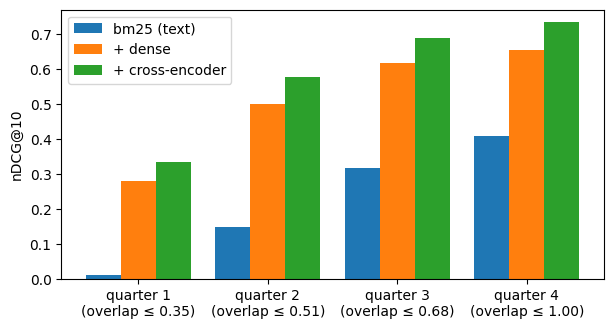

In [47]:
INDEX, _ = ladder.index(fiqa.texts)

def overlap(ds, qid):
    """How much of the question's wording (weighted by idf) its best relevant post contains."""
    weight = {t: INDEX.idf[INDEX.vocab[t]] for t in set(ladder.tokenize(ds.queries[qid])) if t in INDEX.vocab}
    total = sum(weight.values()) or 1.0
    posts = [set(ladder.tokenize(ds.texts[ds.row[d]])) for d, g in ds.qrels[qid].items() if g > 0 and d in ds.row]
    return max((sum(w for t, w in weight.items() if t in p) / total for p in posts), default=0.0)

OVERLAP = np.array([overlap(fiqa, q) for q in fiqa.qids])
quarter = np.digitize(OVERLAP, np.quantile(OVERLAP, [0.25, 0.5, 0.75]))
fig, ax = plt.subplots(figsize=(7, 3.5))
for k, step in enumerate(("bm25 (text)", "+ dense", "+ cross-encoder")):
    ax.bar(np.arange(4) + 0.27 * (k - 1), [np.mean([runs["fiqa"][step][q] for q, b in zip(fiqa.qids, quarter) if b == j])
                                            for j in range(4)], 0.27, label=step)
ax.set_xticks(range(4), [f"quarter {j + 1}\n(overlap ≤ {OVERLAP[quarter == j].max():.2f})" for j in range(4)])
ax.set_ylabel("nDCG@10")
ax.legend()

In [48]:
HARD = sorted(np.random.default_rng(0).choice([q for q, b in zip(fiqa.qids, quarter) if b == 0], 40, replace=False))
qid = HARD[0]
print(fiqa.queries[qid], "\n")
for name, fn in (("bm25_search", bm25_search), ("search", search)):
    found = fn(fiqa, fiqa.queries[qid], qid)
    print(f"{name}: relevant {[fiqa.qrels[qid].get(fiqa.ids[i], 0) for i in found]}")
    print(hits(fiqa, found[:2]), "\n")


How does Walmart account their expired food 

bm25_search: relevant [0, 0, 0, 0, 0]
1. [doc:599998] 
   "Your argument comes down to ""he is presumed guilty until proven innocent"", a common injustice found in many authoritarian dictatorships and theocracies throughout history. Your argument seems based on the assumption that M. Armstrong is guilty without a requirement for any evidence that he did an
2. [doc:572490] 
   &gt;Why does minimum wage exist, if not to account for low skill jobs like those found in Walmart.  Minimum wage exists as a floor, the lowest possible amount someone can survive on. Paying anyone less would make survival impossible, in fact, many wal-mart employees are also on food stamps. 



search: relevant [1, 0, 0, 0, 0]
1. [doc:191649] 
   "Any business, like any household, has items that are wasted. Unlike a household, a business does keep track of all items that are unsellable. Depending on the reason for the item being unsellable they are accounted for differently. Items that can be returned to the manufacturer are done so, and the
2. [doc:599998] 
   "Your argument comes down to ""he is presumed guilty until proven innocent"", a common injustice found in many authoritarian dictatorships and theocracies throughout history. Your argument seems based on the assumption that M. Armstrong is guilty without a requirement for any evidence that he did an 



In [49]:
SYSTEM = ("You answer a financial question using the forum posts in the corpus. Answer concisely and practically. If "
          "the posts do not answer the question, say so. Search with a few focused queries, read the most promising posts, "
          "and cite every post you rely on as [doc:ID].")
TOOLS = [
    dict(type="function", function=dict(name="search", description="Search the forum posts. Returns the 5 best posts with a snippet each.",
                                        parameters=dict(type="object", properties=dict(query=dict(type="string")), required=["query"]))),
    dict(type="function", function=dict(name="read", description="Read one post in full.",
                                        parameters=dict(type="object", properties=dict(doc_id=dict(type="string")), required=["doc_id"]))),
]

def agent(ds, qid, search_with, budget=2, verbose=False):
    """The model answers question qid with up to `budget` turns of tool calls, then one turn with tools off."""
    messages = [dict(role="system", content=SYSTEM), dict(role="user", content=ds.queries[qid])]
    seen, searches, usd = set(), 0, 0.0
    for turn in range(budget + 1):
        if turn == budget:
            messages.append(dict(role="user", content="Tools are off now. Write your final answer from what you have read."))
        reply = chat(messages, TOOLS, "auto" if turn < budget else "none")
        usd += reply["usage"].get("usd", 0)
        msg = reply["choices"][0]["message"]
        messages.append(msg)
        for call in msg.get("tool_calls") or []:
            name, args = call["function"]["name"], json.loads(call["function"]["arguments"])
            if verbose:
                print(f"{name}({args})")
            if name == "search":
                rows = search_with(ds, args["query"], qid)
                seen |= {ds.ids[i] for i in rows}
                searches += 1
                out = hits(ds, rows)
            else:
                out = read(ds, args["doc_id"])
            messages.append(dict(role="tool", tool_call_id=call["id"], content=out))
        if not msg.get("tool_calls"):
            break
    return outcome(ds, qid, msg["content"] or "", seen, searches, usd)

def rag(ds, qid, search_with):
    """Classic RAG: one search with the question itself, the top 5 in the prompt, one answer."""
    rows = search_with(ds, ds.queries[qid], qid)
    reply = chat([dict(role="system", content=SYSTEM),
                  dict(role="user", content=f"{ds.queries[qid]}\n\nSearch results:\n{hits(ds, rows)}")])
    return outcome(ds, qid, reply["choices"][0]["message"]["content"] or "", {ds.ids[i] for i in rows}, 1,
                   reply["usage"].get("usd", 0))

def outcome(ds, qid, answer, seen, searches, usd):
    relevant = lambda d: ds.qrels[qid].get(d, 0) > 0
    cited = set(re.findall(r"\[doc:([^\]]+)\]", answer))
    return dict(answer=answer, searches=searches, usd=usd, seen_relevant=any(map(relevant, seen)),
                cited=len(cited), cited_relevant=sum(map(relevant, cited)))


In [42]:
run = agent(fiqa, qid, search, verbose=True)
print("\n" + run["answer"])
print("\njudge score", ladder.grade(fiqa, qid, run["answer"])["score"])


search({'query': 'Walmart expired food accounting'})
search({'query': 'Walmart inventory shrink expired food write-off'})


read({'doc_id': '191649'})



The forum posts don't describe Walmart's actual accounting for expired food. The closest source is a general forum post, [doc:191649], which is not authoritative and doesn't mention Walmart. It says a business generally:

- Returns unsellable items that can go back to the manufacturer for credit.
- Tracks spoiled food, including scanning meat that has reached its "sell by" date into the computer, so the exact items and their value are recorded.
- Repurposes some items, such as turning bread into bread pudding, marking them down for quick sale, or donating them to charity, and tracks those too.
- Reflects any losses it can't recover in its prices.

For Walmart's specific treatment, such as how the write-off is booked or how it appears in financial statements, you would need its annual report (10-K) or inventory accounting policy. I didn't find those in the corpus.



judge score 0.5


In [43]:

def graded(args):
    method, search_with, qid = args
    run = method(fiqa, qid, search_with)
    g = ladder.grade(fiqa, qid, run["answer"])
    return dict(run, score=g["score"], usd=run["usd"] + g["usd"])

with ThreadPoolExecutor(8) as pool:
    RUNS = {(method.__name__, fn.__name__): list(pool.map(graded, [(method, fn, q) for q in HARD]))
            for method in (rag, agent) for fn in (bm25_search, search)}

print(f"{'':24s}{'judge score':>13s}{'searches':>10s}{'relevant seen':>15s}{'cited relevant':>16s}{'cost':>8s}")
for (method, fn), rs in RUNS.items():
    cited = sum(r["cited"] for r in rs)
    print(f"{method + ', ' + fn:24s}{np.mean([r['score'] for r in rs]):13.3f}{np.mean([r['searches'] for r in rs]):10.1f}"
          f"{np.mean([r['seen_relevant'] for r in rs]):15.0%}{sum(r['cited_relevant'] for r in rs) / max(cited, 1):16.0%}"
          f"{sum(r['usd'] for r in rs):8.3f}")
for method in ("rag", "agent"):
    diff = np.array([b["score"] - a["score"] for a, b in zip(RUNS[method, "bm25_search"], RUNS[method, "search"])])
    print(f"{method}: search − bm25_search {diff.mean():+.3f} ± {1.96 * diff.std() / np.sqrt(len(diff)):.3f} (95%)")


                          judge score  searches  relevant seen  cited relevant    cost
rag, bm25_search                0.362       1.0             0%              0%   0.022
rag, search                     0.500       1.0            48%             13%   0.026
agent, bm25_search              0.450       2.6            12%              4%   0.046
agent, search                   0.550       2.2            48%             13%   0.044
rag: search − bm25_search +0.138 ± 0.077 (95%)
agent: search − bm25_search +0.100 ± 0.079 (95%)
